# Bab 6: Advanced Logistic Regression and Extensions

Notebook ini merangkum Bab 6 buku *scikit-learn Cookbook* (Third Edition) karya John Sukup. Banyak orang langsung membayangkan regresi untuk memprediksi angka, padahal regresi logistik dipakai untuk memprediksi kategori. Di bab ini kita mendalami regresi logistik: klasifikasi multikelas, regularisasi, klasifikasi multilabel, dan metrik evaluasi.

Isi notebook:

1. Gambaran umum regresi logistik
2. Klasifikasi multikelas (one-vs-rest dan multinomial)
3. Regularisasi pada regresi logistik (L1 dan L2)
4. Klasifikasi multilabel
5. Metrik evaluasi model
6. Latihan praktik

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.datasets import (load_breast_cancer, load_iris,
                              make_multilabel_classification, make_classification)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score,
                             roc_curve, auc)

pd.set_option("display.precision", 4)


def styled_report(y_true, y_pred, **kwargs):
    """Classification report sebagai DataFrame berwarna."""
    rep = pd.DataFrame(classification_report(y_true, y_pred, output_dict=True, **kwargs)).transpose()
    return (rep.style
            .background_gradient(cmap="Blues", subset=["precision", "recall", "f1-score"])
            .format({"precision": "{:.3f}", "recall": "{:.3f}",
                     "f1-score": "{:.3f}", "support": "{:.0f}"}))

## 1. Overview of Logistic Regression

Regresi logistik adalah metode statistik dasar untuk klasifikasi biner. Berbeda dari regresi linear yang menghasilkan angka kontinu, regresi logistik memprediksi **probabilitas** sebuah observasi masuk ke kelas tertentu. Caranya: kombinasi linear dari fitur dilewatkan ke **fungsi logistik (sigmoid)** sehingga hasilnya selalu berada antara 0 dan 1.

P(Y = 1 | X) = 1 / (1 + e^−(β0 + β1X1 + ... + βnXn))

Koefisien β diestimasi dengan **maximum likelihood estimation (MLE)**. Hasil probabilitas diubah jadi kelas lewat ambang (threshold), umumnya 0.5. Contoh pemakaiannya: menentukan apakah email itu spam, atau apakah pasien menderita penyakit tertentu berdasarkan hasil pengukuran medis.

Disini pakai dataset Breast Cancer bawaan scikit-learn, salah satu toy dataset yang paling sering dipakai.

In [2]:
data = load_breast_cancer()
X = data.data
y = data.target

df = pd.DataFrame(X, columns=data.feature_names)
df["target"] = y

X_train, X_test, y_train, y_test = train_test_split(
    df[data.feature_names], df["target"], test_size=0.2, random_state=2024)

X_train.shape, X_test.shape

((455, 30), (114, 30))

In [3]:
# Buat dan latih model. max_iter dinaikkan supaya solver bisa konvergen
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")

Accuracy: 0.95


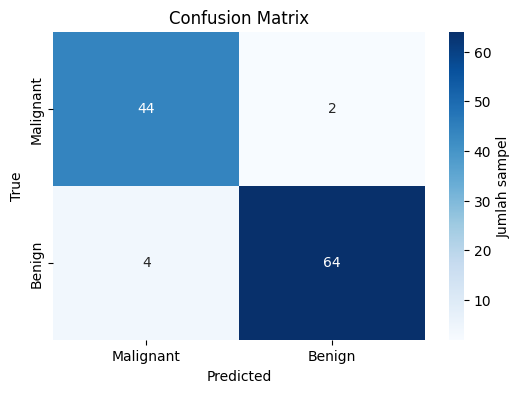

In [4]:
class_names = ["Malignant", "Benign"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={"label": "Jumlah sampel"})
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

In [5]:
display(styled_report(y_test, y_pred, target_names=class_names))

,precision,recall,f1-score,support
Malignant,0.917,0.957,0.936,46
Benign,0.970,0.941,0.955,68
accuracy,0.947,0.947,0.947,1
macro avg,0.943,0.949,0.946,114
weighted avg,0.948,0.947,0.948,114


Model langsung memberi hasil bagus tanpa pengaturan khusus, dengan sangat sedikit salah klasifikasi. Tapi accuracy sendirian tidak selalu metrik terbaik, apalagi untuk kasus seperti ini, ketika yang diprediksi adalah kemungkinan seseorang menderita kanker. Pada kasus semacam itu, kegagalan mendeteksi kasus ganas (recall rendah) jauh lebih mahal daripada alarm palsu.

### Cara Kerja

Koefisien hasil training menunjukkan seberapa besar tiap fitur berkontribusi pada probabilitas masuk ke suatu kelas. Batas keputusan regresi logistik bersifat linear pada skala **log-odds**.

> **Log-odds**: logaritma natural dari odds. Odds adalah rasio probabilitas suatu kejadian terjadi terhadap probabilitas kejadian itu tidak terjadi (seperti pada taruhan). Transformasi ini memetakan probabilitas yang terikat 0 sampai 1 ke skala linear tak terbatas, dari negatif tak hingga sampai positif tak hingga.

Beberapa metrik untuk mengevaluasi regresi logistik:

- **Accuracy**: proporsi prediksi yang benar.
- **Confusion matrix**: rincian true positive, true negative, false positive, dan false negative.
- **Precision dan recall**: seberapa baik model menemukan kasus positif dibanding semua kasus.
- **ROC curve**: performa di berbagai ambang probabilitas (dibahas di bagian 5).

## 2. Multiclass Classification Techniques

Dunia nyata jarang sesederhana 0 atau 1. Kalau hasil yang dicari punya lebih dari dua kelas, regresi logistik masih bisa dipakai lewat dua strategi:

- **One-vs-Rest (OvR)**: melatih satu classifier biner per kelas. Untuk tiap classifier, kelas itu dianggap positif dan semua kelas lain negatif. Saat prediksi, classifier dengan skor keyakinan tertinggi yang dipilih.
- **Multinomial (softmax regression)**: memodelkan probabilitas semua kelas sekaligus dengan fungsi softmax, dengan satu set koefisien per kelas yang dioptimasi bersamaan. Cocok kalau kelas-kelasnya saling eksklusif.

Kita pakai dataset Iris yang punya tiga kelas.

In [6]:
iris = load_iris()
Xi, yi = iris.data, iris.target
feature_names = iris.feature_names

df_iris = pd.DataFrame(Xi, columns=feature_names)
df_iris["target"] = yi

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=2024)

Catatan versi: buku memakai argumen `multi_class='multinomial'` pada `LogisticRegression`. Argumen itu sudah dihapus di scikit-learn versi baru (1.7 ke atas), dan perilakunya kini selalu multinomial untuk tiga kelas atau lebih. Supaya kode tetap jalan di versi mana pun, di bawah ini OvR dibuat eksplisit dengan `OneVsRestClassifier`, sedangkan model multinomial cukup memakai solver `lbfgs` (bawaan).

In [7]:
# One-vs-Rest: satu classifier biner per kelas
ovr_model = OneVsRestClassifier(LogisticRegression(solver="liblinear"))
ovr_model.fit(Xi_train, yi_train)
y_pred_ovr = ovr_model.predict(Xi_test)

# Multinomial (softmax)
multinomial_model = LogisticRegression(solver="lbfgs", max_iter=1000)
multinomial_model.fit(Xi_train, yi_train)
y_pred_multi = multinomial_model.predict(Xi_test)

print(f"Accuracy OvR        : {accuracy_score(yi_test, y_pred_ovr):.3f}")
print(f"Accuracy Multinomial: {accuracy_score(yi_test, y_pred_multi):.3f}")

Accuracy OvR        : 0.956
Accuracy Multinomial: 0.933


In [8]:
print("One-vs-Rest (OvR) Logistic Regression")
display(styled_report(yi_test, y_pred_ovr, target_names=iris.target_names))

One-vs-Rest (OvR) Logistic Regression


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.917,0.917,0.917,12
virginica,0.933,0.933,0.933,15
accuracy,0.956,0.956,0.956,1
macro avg,0.950,0.950,0.950,45
weighted avg,0.956,0.956,0.956,45


In [9]:
print("Multinomial Logistic Regression")
display(styled_report(yi_test, y_pred_multi, target_names=iris.target_names))

Multinomial Logistic Regression


,precision,recall,f1-score,support
setosa,1.000,1.000,1.000,18
versicolor,0.846,0.917,0.880,12
virginica,0.929,0.867,0.897,15
accuracy,0.933,0.933,0.933,1
macro avg,0.925,0.928,0.926,45
weighted avg,0.935,0.933,0.934,45


Di laporan klasifikasi ada dua baris rata-rata yang perlu dibedakan:

- **macro avg**: rata-rata tiap kelas tanpa memperhitungkan jumlah sampel (support).
- **weighted avg**: rata-rata yang dibobot dengan jumlah sampel tiap kelas.

Karena datanya kecil dan seimbang, kedua nilai ini nyaris sama.

### Hal yang Perlu Diingat

- **Pemilihan solver**: `liblinear` cocok untuk OvR, sedangkan `lbfgs` atau `newton-cg` umum dipakai untuk multinomial.
- **Regularisasi**: regresi logistik multikelas juga mendapat manfaat dari regularisasi untuk mencegah overfitting.
- **Preprocessing**: fitur numerik yang diskalakan ke rentang standar sering meningkatkan performa.

### Visualisasi dengan Pairplot

Pairplot dari seaborn menunjukkan seberapa baik fitur memisahkan kelas.

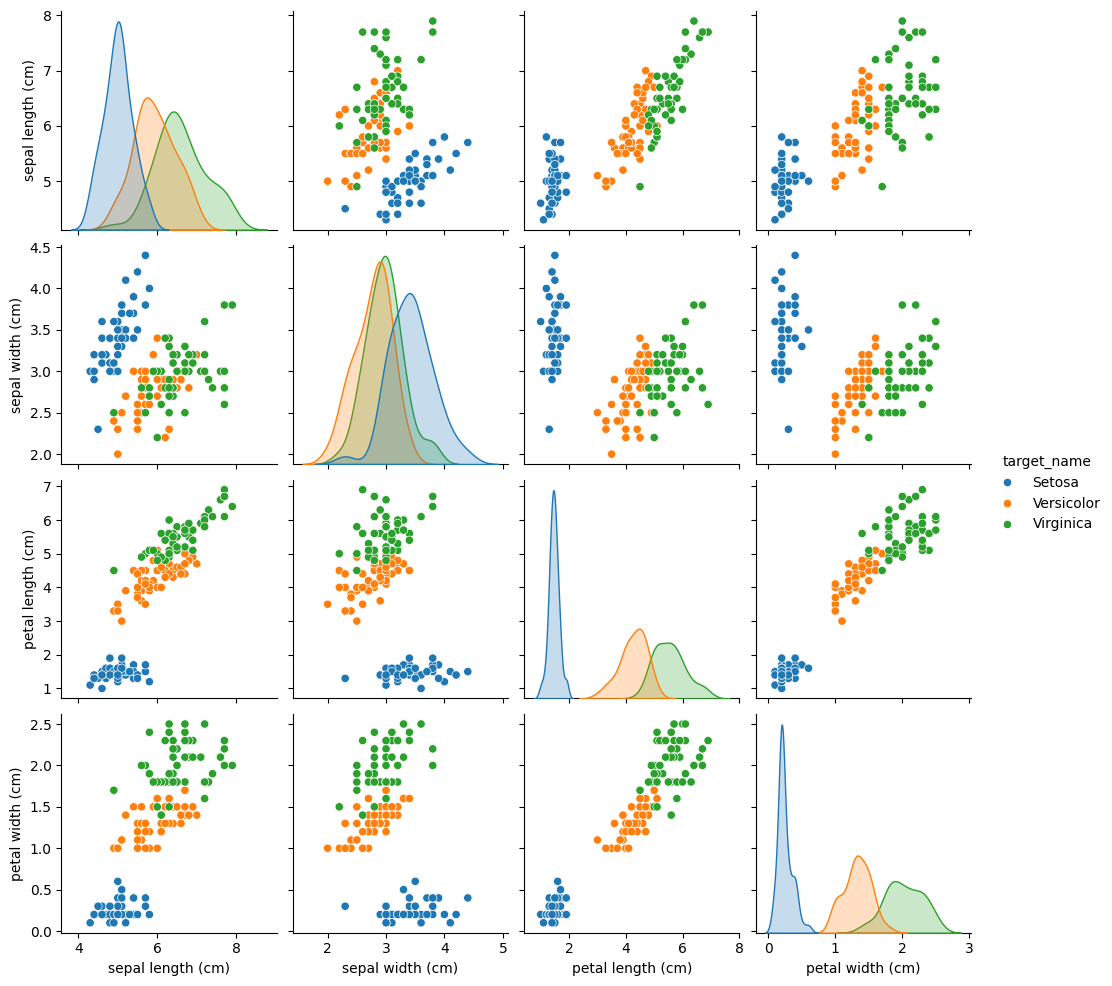

In [10]:
target_names = {0: "Setosa", 1: "Versicolor", 2: "Virginica"}
df_iris["target_name"] = df_iris["target"].map(target_names)

sns.pairplot(df_iris.drop(columns="target"), hue="target_name", diag_kind="kde")
plt.show()

Dari pairplot terlihat bahwa `petal length` dan `petal width` punya distribusi yang sempit dan runcing (kurtosis tinggi), dan antar kelas hampir tidak tumpang tindih. Ini menjelaskan mengapa dua fitur tersebut sangat berguna untuk klasifikasi Iris.

Kita juga bisa melihat batas keputusan model memakai dua fitur saja (petal length dan petal width).

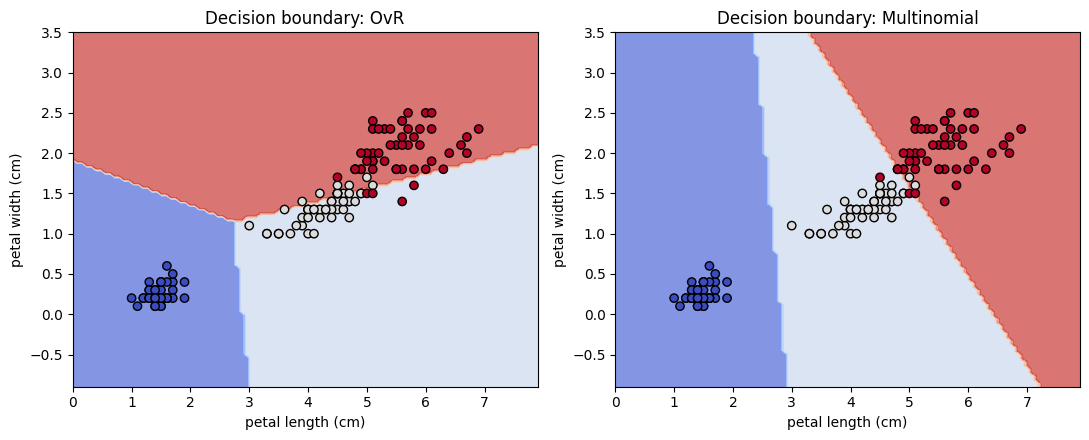

In [11]:
from sklearn.inspection import DecisionBoundaryDisplay

X2 = Xi[:, 2:4]  # petal length, petal width
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, yi, test_size=0.3, random_state=2024)

models_2d = {
    "OvR": OneVsRestClassifier(LogisticRegression(solver="liblinear")),
    "Multinomial": LogisticRegression(solver="lbfgs", max_iter=1000),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(X2_train, y2_train)
    DecisionBoundaryDisplay.from_estimator(
        m, X2, response_method="predict", cmap=plt.cm.coolwarm,
        alpha=0.7, ax=ax, xlabel="petal length (cm)", ylabel="petal width (cm)")
    ax.scatter(X2[:, 0], X2[:, 1], c=yi, edgecolors="k", cmap=plt.cm.coolwarm)
    ax.set_title(f"Decision boundary: {name}")
plt.tight_layout()
plt.show()

## 3. Regularization in Logistic Regression

Regularisasi menambahkan penalti pada fungsi loss supaya koefisien tidak terlalu besar. Ini penting untuk mencegah overfitting, terutama pada data berdimensi tinggi. Seperti di Bab 5, ada dua jenis:

- **Ridge (L2)**: penalti sebanding dengan kuadrat besar koefisien. Koefisien menyusut mendekati nol, tapi jarang tepat nol.
- **Lasso (L1)**: penalti sebanding dengan nilai absolut koefisien. Sebagian koefisien bisa tepat nol, sehingga sekaligus berfungsi sebagai seleksi fitur.

Pada `LogisticRegression`, kekuatan regularisasi diatur oleh parameter `C`, yang merupakan **kebalikan** dari kekuatan regularisasi: makin kecil `C`, makin kuat regularisasinya.

Karena regularisasi sensitif terhadap skala fitur, data distandardisasi dulu.

In [12]:
data = load_breast_cancer()
X, y = data.data, data.target
feature_names = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [13]:
ridge_model = LogisticRegression(penalty="l2", solver="liblinear", C=0.1)
ridge_model.fit(X_train, y_train)

lasso_model = LogisticRegression(penalty="l1", solver="liblinear", C=0.1)
lasso_model.fit(X_train, y_train)

y_pred_ridge = ridge_model.predict(X_test)
y_pred_lasso = lasso_model.predict(X_test)

print(f"Accuracy Ridge (L2): {accuracy_score(y_test, y_pred_ridge):.3f}")
print(f"Accuracy Lasso (L1): {accuracy_score(y_test, y_pred_lasso):.3f}")
print(f"Koefisien nol pada Ridge: {(ridge_model.coef_ == 0).sum()}")
print(f"Koefisien nol pada Lasso: {(lasso_model.coef_ == 0).sum()}")

Accuracy Ridge (L2): 0.982
Accuracy Lasso (L1): 0.965
Koefisien nol pada Ridge: 0
Koefisien nol pada Lasso: 23


In [14]:
print("Ridge (L2) Regularized Logistic Regression")
display(styled_report(y_test, y_pred_ridge))

Ridge (L2) Regularized Logistic Regression


,precision,recall,f1-score,support
0,0.985,0.970,0.977,67
1,0.981,0.990,0.986,104
accuracy,0.982,0.982,0.982,1
macro avg,0.983,0.980,0.982,171
weighted avg,0.982,0.982,0.982,171


In [15]:
print("Lasso (L1) Regularized Logistic Regression")
display(styled_report(y_test, y_pred_lasso))

Lasso (L1) Regularized Logistic Regression


,precision,recall,f1-score,support
0,0.930,0.985,0.957,67
1,0.990,0.952,0.971,104
accuracy,0.965,0.965,0.965,1
macro avg,0.960,0.968,0.964,171
weighted avg,0.966,0.965,0.965,171


Kedua model bagus, dan mana yang lebih unggul bergantung pada metrik yang dipilih. Di contoh buku, Lasso punya accuracy sedikit lebih rendah, tetapi precision dan recall keduanya bisa saling mengungguli pada kelas yang berbeda. Perhatikan juga baris "koefisien nol" di atas: hanya Lasso yang menggugurkan fitur.

### Hal yang Perlu Diingat

- **Solver**: `liblinear` mendukung L1 dan L2 untuk dataset kecil. Untuk dataset besar, `saga` sering jadi pilihan.
- **Skala data**: karena regularisasi sensitif terhadap skala, standardisasi hampir selalu diperlukan.
- **Tuning `C`**: cari nilai `C` terbaik dengan grid search atau random search, seperti hyperparameter lain.

### Efek Regularisasi pada Koefisien

Dengan memvariasikan `C`, kita bisa melihat bagaimana koefisien menyusut.

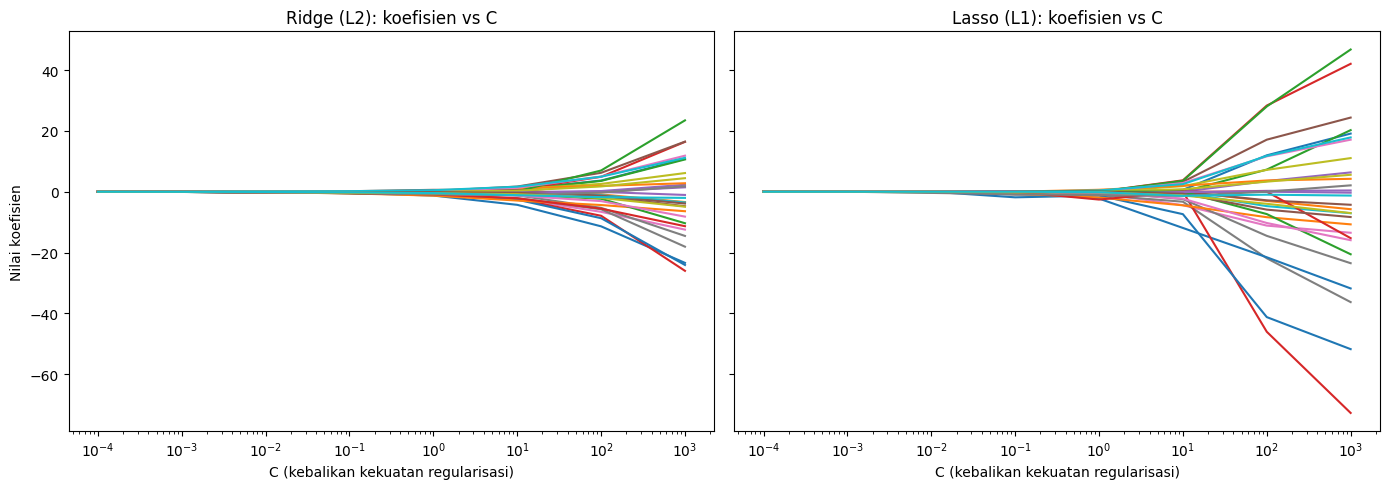

In [16]:
C_values = np.array([0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000])


def coef_path(penalty):
    coefs = []
    for C in C_values:
        m = LogisticRegression(penalty=penalty, solver="liblinear", C=C)
        m.fit(X_train, y_train)
        coefs.append(m.coef_[0])
    return np.array(coefs)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (pen, title) in zip(axes, [("l2", "Ridge (L2)"), ("l1", "Lasso (L1)")]):
    path = coef_path(pen)
    for i in range(X.shape[1]):
        ax.plot(C_values, path[:, i])
    ax.set_xscale("log")
    ax.set_xlabel("C (kebalikan kekuatan regularisasi)")
    ax.set_title(f"{title}: koefisien vs C")
axes[0].set_ylabel("Nilai koefisien")
plt.tight_layout()
plt.show()

Pada plot Ridge, koefisien menyusut mulus mendekati nol saat `C` mengecil. Pada plot Lasso, banyak koefisien langsung menjadi nol tepat, dan hanya fitur yang paling berpengaruh yang bertahan sampai `C` cukup besar.

## 4. Multilabel Classification Concepts

Pada klasifikasi multilabel, satu observasi bisa punya **beberapa label sekaligus**. Contohnya kategorisasi teks (satu artikel bisa bertopik olahraga dan politik), penandaan gambar, dan bioinformatika. Bedanya dengan multikelas: pada multikelas setiap observasi hanya punya satu kelas.

Kita buat data sintetis dengan `make_multilabel_classification()`. Argumen `n_labels` tidak menjamin jumlah label persis per record, hanya rata-rata yang diizinkan.

In [17]:
X, y = make_multilabel_classification(
    n_samples=1000, n_features=20, n_classes=5, n_labels=2, random_state=2024)

df_ml = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(X.shape[1])])
df_ml["target"] = list(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)
y.shape

(1000, 5)

Strategi paling sederhana adalah OvR: latih satu model biner untuk setiap label (kolom `y`).

In [18]:
models = []
y_pred_all = []

for i in range(y_train.shape[1]):
    m = LogisticRegression(solver="liblinear")
    m.fit(X_train, y_train[:, i])
    models.append(m)
    y_pred_all.append(m.predict(X_test))

# Susun ulang agar bentuknya sama dengan y_test (sampel x label)
y_pred = np.array(y_pred_all).T

print(f"Subset accuracy: {accuracy_score(y_test, y_pred):.3f}")
display(styled_report(y_test, y_pred, zero_division=1))

Subset accuracy: 0.340


,precision,recall,f1-score,support
0,0.808,0.813,0.811,166
1,0.801,0.845,0.823,181
2,0.674,0.333,0.446,93
3,0.750,0.176,0.286,34
4,0.575,0.477,0.522,88
micro avg,0.757,0.653,0.701,562
macro avg,0.722,0.529,0.577,562
weighted avg,0.744,0.653,0.677,562
samples avg,0.787,0.782,0.680,562


Subset accuracy di scikit-learn untuk multilabel itu ketat: sebuah prediksi dianggap benar hanya kalau **semua** label cocok. Karena itu angkanya biasanya jauh lebih rendah daripada precision atau recall per label, dan klasifikasi multilabel memang lebih sulit daripada kasus biner di atas.

> **`MultiOutputClassifier`**: scikit-learn menyediakan kelas ini sebagai jalan pintas. Kita beri satu classifier (misalnya `LogisticRegression()`), dan ia menerapkannya ke tiap target. Kodenya jadi lebih ringkas daripada loop manual di atas.

In [19]:
# Versi ringkas dengan MultiOutputClassifier
multi = MultiOutputClassifier(LogisticRegression(solver="liblinear"))
multi.fit(X_train, y_train)
print(f"Subset accuracy (MultiOutputClassifier): {accuracy_score(y_test, multi.predict(X_test)):.3f}")

Subset accuracy (MultiOutputClassifier): 0.340


### Visualisasi Co-occurrence Label

Matriks co-occurrence menunjukkan label mana yang sering muncul bersamaan. Fungsi di bawah menampilkan jumlah mentah dan versi relatif (dinormalisasi dengan diagonal), plus statistik frekuensi dan kombinasi label yang paling umum.

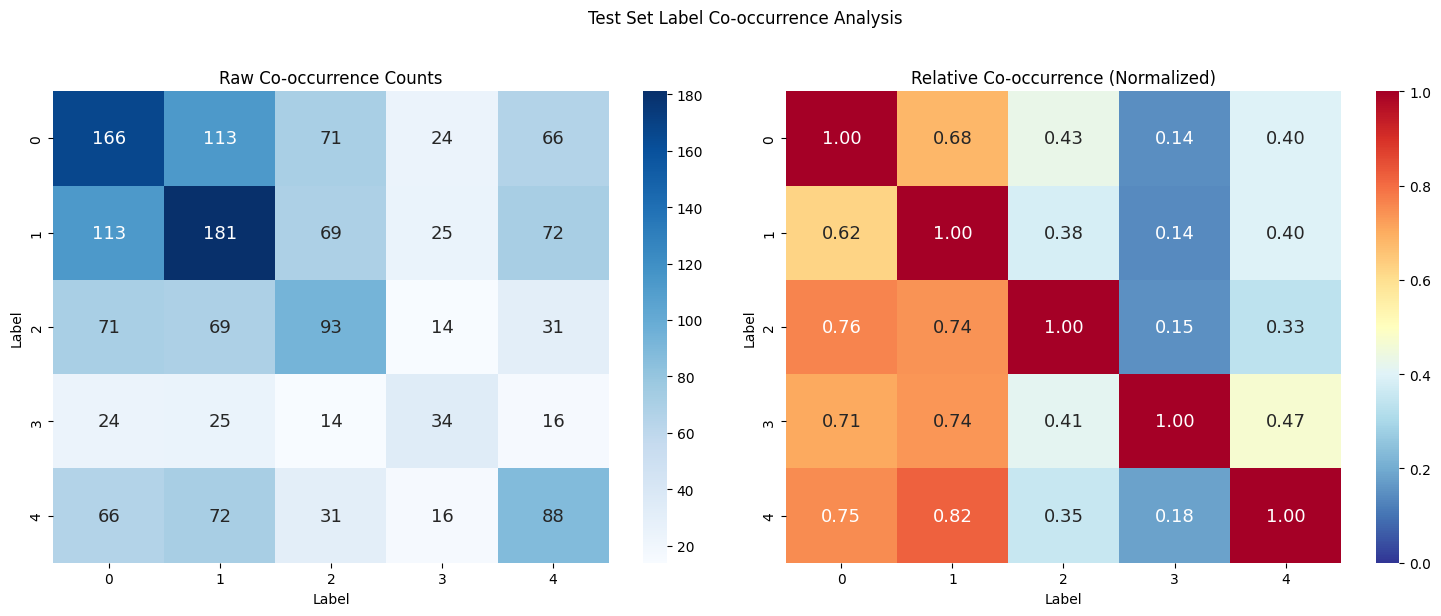

Label statistics
Total samples: 300
Label frequencies:
  Label 0: 166 samples (55.3%)
  Label 1: 181 samples (60.3%)
  Label 2: 93 samples (31.0%)
  Label 3: 34 samples (11.3%)
  Label 4: 88 samples (29.3%)
Most common label combinations:
  [0 0 0 0 0]: 52 samples (17.3%)
  [0 1 0 0 0]: 34 samples (11.3%)
  [1 1 0 0 0]: 28 samples (9.3%)
  [1 1 1 0 0]: 25 samples (8.3%)
  [1 1 0 0 1]: 24 samples (8.0%)


In [20]:
def plot_label_cooccurrence(y, title="Label Co-occurrence Analysis"):
    cooccurrence = y.T @ y
    diag = np.diag(cooccurrence)
    relative = cooccurrence / diag[:, None]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    sns.heatmap(cooccurrence, annot=True, fmt="d", cmap="Blues",
                ax=ax1, annot_kws={"fontsize": 13})
    ax1.set_title("Raw Co-occurrence Counts")
    ax1.set_xlabel("Label")
    ax1.set_ylabel("Label")

    sns.heatmap(relative, annot=True, fmt=".2f", cmap="RdYlBu_r",
                ax=ax2, annot_kws={"fontsize": 13}, vmin=0, vmax=1)
    ax2.set_title("Relative Co-occurrence (Normalized)")
    ax2.set_xlabel("Label")
    ax2.set_ylabel("Label")

    plt.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

    print("Label statistics")
    print(f"Total samples: {len(y)}")
    print("Label frequencies:")
    for i in range(y.shape[1]):
        count = y[:, i].sum()
        print(f"  Label {i}: {count} samples ({count / len(y) * 100:.1f}%)")

    print("Most common label combinations:")
    combos, counts = np.unique(y, axis=0, return_counts=True)
    order = np.argsort(-counts)
    for combo, count in zip(combos[order][:5], counts[order][:5]):
        print(f"  {combo}: {count} samples ({count / len(y) * 100:.1f}%)")


plot_label_cooccurrence(y_test, "Test Set Label Co-occurrence Analysis")

Cara membaca matriks:

- **Matriks mentah (kiri)**: sel (i, j) adalah berapa kali label i dan j muncul bersama. Diagonal adalah total kemunculan tiap label. Angka besar berarti kedua label sering muncul berbarengan.
- **Matriks relatif (kanan)**: sel (i, j) adalah proporsi kemunculan label i yang disertai label j. Nilai mendekati 1 berarti kalau i muncul, j hampir selalu ikut. Nilai mendekati 0 berarti keduanya jarang muncul bersama.
- Pola yang tidak simetris pada matriks relatif menunjukkan ketergantungan searah. Misalnya label A selalu disertai label B, sedangkan B bisa muncul tanpa A.
- Kombinasi label dibaca dari kiri ke kanan per label. `[1 1 0 0 0]` artinya label 0 dan 1 ada, label 2, 3, dan 4 tidak ada.

Selain OvR, ada pendekatan lain seperti **binary relevance** dan **classifier chains**, yang masing-masing punya kelebihan dan kekurangan tergantung hubungan antar label.

## 5. Model Evaluation Metrics

Evaluasi menjawab pertanyaan apakah model akan bekerja baik pada data baru dan di mana ia lemah. Metrik utama yang dibahas:

- **Accuracy**: ketepatan keseluruhan prediksi.
- **Precision**: dari semua yang diprediksi positif, berapa yang benar-benar positif.
- **Recall**: dari semua yang sebenarnya positif, berapa yang berhasil ditemukan.
- **F1-score**: rata-rata harmonik precision dan recall.
- **ROC curve**: true positive rate terhadap false positive rate pada berbagai ambang.
- **AUC**: luas di bawah kurva ROC, ringkasan kemampuan model membedakan kelas positif dan negatif dalam satu angka.

In [21]:
data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2024)

model = LogisticRegression(solver="liblinear")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

print(f"Accuracy  {accuracy:.2f}")
print(f"Precision {precision:.2f}")
print(f"Recall    {recall:.2f}")
print(f"F1 Score  {f1:.2f}")
print(f"ROC AUC   {roc_auc:.2f}")
print()
print(classification_report(y_test, y_pred))

Accuracy  0.94
Precision 0.94
Recall    0.95
F1 Score  0.95
ROC AUC   0.99

              precision    recall  f1-score   support

           0       0.92      0.91      0.92        67
           1       0.94      0.95      0.95       104

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



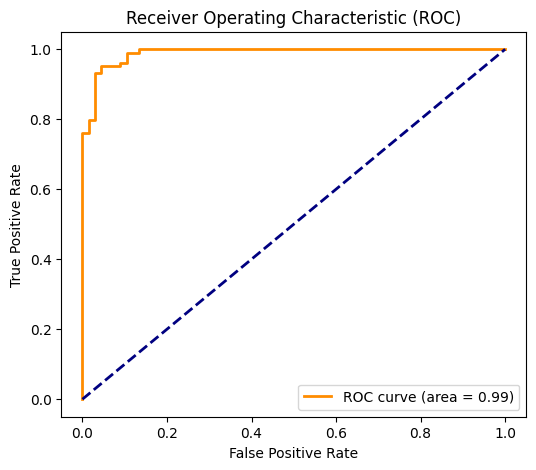

In [22]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {roc_auc:.2f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.show()

Garis putus-putus adalah model yang tidak lebih baik dari menebak acak. Kurva yang baik bergerak ke pojok kiri atas: true positive rate tinggi dengan false positive rate rendah. AUC yang lebih besar berarti model lebih baik, dan nilai 1.0 adalah klasifikasi sempurna.

Metrik mana yang dipilih tergantung tujuan. Kalau false positive mahal, precision lebih penting. Kalau yang penting adalah menangkap sebanyak mungkin kasus positif, recall lebih penting.

## 6. Practical Exercises with Advanced Logistic Regression

Tiga latihan di akhir bab, lengkap dengan kode pengerjaan.

### Latihan 1: Membangun Model Logistic Regression Teregularisasi

Memakai dataset Breast Cancer dengan regularisasi Lasso dan Ridge.

In [23]:
data = load_breast_cancer()
X_tr, X_te, y_tr, y_te = train_test_split(
    data.data, data.target, test_size=0.3, random_state=2024)

sc = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = sc.transform(X_tr), sc.transform(X_te)

for pen in ["l1", "l2"]:
    clf = LogisticRegression(penalty=pen, solver="liblinear", C=0.5)
    clf.fit(X_tr_s, y_tr)
    pred = clf.predict(X_te_s)
    print(f"--- Penalty {pen.upper()} ---")
    print(f"Accuracy: {accuracy_score(y_te, pred):.3f}")
    print(classification_report(y_te, pred))

--- Penalty L1 ---
Accuracy: 0.971
              precision    recall  f1-score   support

           0       0.94      0.99      0.96        67
           1       0.99      0.96      0.98       104

    accuracy                           0.97       171
   macro avg       0.97      0.97      0.97       171
weighted avg       0.97      0.97      0.97       171

--- Penalty L2 ---
Accuracy: 0.982
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        67
           1       1.00      0.97      0.99       104

    accuracy                           0.98       171
   macro avg       0.98      0.99      0.98       171
weighted avg       0.98      0.98      0.98       171



### Latihan 2: Mengevaluasi Regresi Logistik Multikelas

Model multinomial pada dataset Iris.

Accuracy: 0.933
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        18
  versicolor       0.85      0.92      0.88        12
   virginica       0.93      0.87      0.90        15

    accuracy                           0.93        45
   macro avg       0.92      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



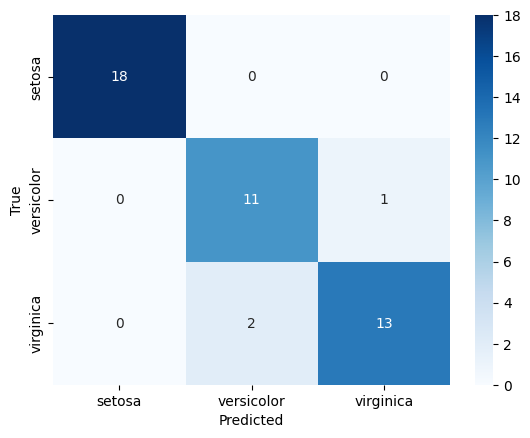

In [24]:
iris = load_iris()
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(
    iris.data, iris.target, test_size=0.3, random_state=2024)

multi_clf = LogisticRegression(solver="lbfgs", max_iter=1000)
multi_clf.fit(Xi_tr, yi_tr)
pred = multi_clf.predict(Xi_te)

print(f"Accuracy: {accuracy_score(yi_te, pred):.3f}")
print(classification_report(yi_te, pred, target_names=iris.target_names))

sns.heatmap(confusion_matrix(yi_te, pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

### Latihan 3: Visualisasi Hasil Logistic Regression

Batas keputusan model pada dataset biner sintetis dengan dua fitur.

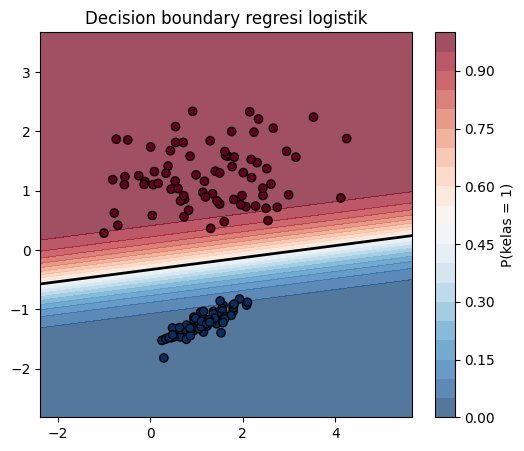

In [25]:
Xs, ys = make_classification(
    n_samples=500, n_features=2, n_redundant=0, n_informative=2,
    n_clusters_per_class=1, class_sep=1.2, random_state=2024)

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(Xs, ys, test_size=0.3, random_state=2024)

clf = LogisticRegression().fit(Xs_tr, ys_tr)

# Mesh grid untuk menggambar probabilitas di seluruh ruang fitur
xx, yy = np.meshgrid(
    np.linspace(Xs[:, 0].min() - 1, Xs[:, 0].max() + 1, 300),
    np.linspace(Xs[:, 1].min() - 1, Xs[:, 1].max() + 1, 300))
probs = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(6, 5))
cs = ax.contourf(xx, yy, probs, levels=20, cmap="RdBu_r", alpha=0.7)
plt.colorbar(cs, ax=ax, label="P(kelas = 1)")
ax.contour(xx, yy, probs, levels=[0.5], colors="k", linewidths=2)
ax.scatter(Xs_te[:, 0], Xs_te[:, 1], c=ys_te, edgecolors="k", cmap="RdBu_r")
ax.set_title("Decision boundary regresi logistik")
plt.show()

## Poin-poin Penting Bab 6

- Regresi logistik memodelkan probabilitas kelas lewat fungsi sigmoid pada kombinasi linear fitur, dan diestimasi dengan maximum likelihood.
- Untuk lebih dari dua kelas, ada OvR (satu model biner per kelas) dan multinomial/softmax (semua kelas dimodelkan sekaligus). Pada scikit-learn versi baru, multinomial adalah perilaku bawaan.
- Regularisasi L2 (Ridge) mengecilkan koefisien, sedangkan L1 (Lasso) bisa menolkan koefisien sehingga berfungsi sebagai seleksi fitur. Parameter `C` adalah kebalikan dari kekuatan regularisasi, dan data sebaiknya distandardisasi.
- Pada klasifikasi multilabel, satu observasi bisa punya beberapa label. Strateginya melatih satu model per label (OvR atau `MultiOutputClassifier`), dengan evaluasi yang lebih ketat.
- Accuracy hanyalah satu sisi. Precision, recall, F1, ROC, dan AUC memberi gambaran yang lebih lengkap, dan pilihan metrik tergantung biaya tiap jenis kesalahan.

Referensi: Sukup, J. (2025). *scikit-learn Cookbook*, Third Edition, Bab 6 "Advanced Logistic Regression and Extensions". Packt Publishing.